# PCE during arithmetic task
The dataset allows to use PCE to see the change in synchronization before and during an arithmetic task.

## Setup

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import mne
import pandas as pd
from pathlib import Path

Fs = 500
DATA_FOLDER = Path("data/calculia")
RESULTS_FOLDER = Path("results")
FIGURES_FOLDER = Path(".Presentation/Figures")

WINDOW_SIZE = 10 # s
DECIMATE = False

# Channel names
CHANNELS = {
    "ANT_FRONTAL" : ["Fp1", "Fp2"],
    "FRONTAL" : ["F3", "F4", "Fz", "F7", "F8"],
    "CENTRAL" : ["C3", "C4", "Cz"],
    "PARIETAL" : ["P3", "P4", "Pz"],
    "OCCIPITAL" : ["O1", "O2"],
    "TEMPORAL" : ["T3", "T4", "T5", "T6"],
}

all_channels = []
for chs in CHANNELS.values():
    all_channels += chs
CHANNELS["ALL_CHANNELS"] = all_channels
CHANNELS["ALL_FRONTAL"] = CHANNELS["ANT_FRONTAL"] + CHANNELS["FRONTAL"]

Plot default settings

In [62]:
import matplotlib.font_manager as fm

BG_COLOR = "#f5f5f0"
CAPTION_COLOR = "#222222"
SUPPORT_COLOR = "#666666"

INTER_FONT_PATH = ".Presentation\\font\\Inter-Regular.ttf"   # a list of .ttf paths
fm.fontManager.addfont(INTER_FONT_PATH)
plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "text.color": CAPTION_COLOR,
    "axes.labelcolor": SUPPORT_COLOR,
    "xtick.color": SUPPORT_COLOR,
    "ytick.color": SUPPORT_COLOR,
    "figure.dpi": 110,
    "savefig.dpi": 600,
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Import data
Read edf files and evaluate PCE

In [63]:
from _PCE import PCE_by_band

PCEs = []

for sbj_id in range(36):
    sbj = f"Subject{sbj_id:02d}"
    rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
    calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"Subject{sbj_id:02d}_2.edf", verbose=False)


    for name, channels in CHANNELS.items():           
        rest_np = np.array(rest_raw[["EEG " + ch for ch in channels]][0])
        rest = PCE_by_band(rest_np, Fs = Fs, window_size=WINDOW_SIZE, do_decimate = DECIMATE)
        for result in rest:
            PCEs.append({
                "Subject" : sbj,
                "Location" : name,
                "Band" : result["band"],
                "Rest" : 1,
                "PCE" : result["PCE"]
            }) 

        calc_np = np.array(calc_raw[["EEG " + ch for ch in channels]][0])
        calc = PCE_by_band(calc_np, Fs = Fs, window_size=WINDOW_SIZE, do_decimate = DECIMATE)
        for result in calc:
                PCEs.append({
                    "Subject" : sbj,
                    "Location" : name,
                    "Band" : result["band"],
                    "Rest" : 0,
                    "PCE" : result["PCE"]
                }) 


df_results = pd.DataFrame(PCEs)
df_results.to_csv(RESULTS_FOLDER / "arithmetic pce.csv")
# df_results.head()

Merge user information

In [64]:
user_df = pd.read_csv(DATA_FOLDER / "subject-info.csv")
df = df_results.merge(user_df, on = "Subject")
df["Male"] = df.Gender.map({"M" : 1, "F" : 0})
df = df.drop(columns=["Recording year", "Number of subtractions", "Gender"])

del df_results

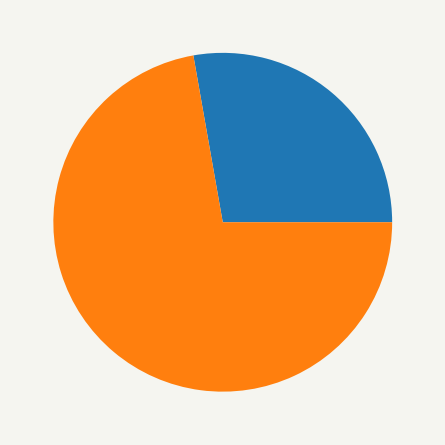

In [65]:
counters = {
    "Poor Counters" : len(user_df[user_df["Count quality"] == 0]),
    "Good Counters" : len(user_df[user_df["Count quality"] == 1]),
}

fig, ax = plt.subplots(figsize=(5, 5))
pie = ax.pie(counters.values())#, labels = counters.keys())
# ax.pie_label(pie, counters.values(),
#             textprops=dict(size=13, weight="bold"))

plt.savefig(FIGURES_FOLDER / "pie.png", dpi = 600)
plt.show()

## Good vs bad counters
Evaluate which location and frequency band change the most between good and poor counters. This is the same test used in the paper for sleep

In [66]:
from scipy.stats import mannwhitneyu
from _functions import cohen_d

res = []
ttest = []

for rest in [0, 1, 2]:
    rest_mask = df["Rest"] == rest
    df_rest = df.loc[rest_mask, :]
    
    if rest == 2:
        df_rest = df[df["Rest"] == 0].copy()
        df_rest["PCE"] = df_rest["PCE"].values -df.loc[df["Rest"] == 1, "PCE"].values # type: ignore

    
    good_counters_mask = df_rest["Count quality"] == 1
        
    for ch in list(CHANNELS.keys()):
        channel_mask = df_rest["Location"] == ch
        for band in df_rest["Band"].unique():
            band_mask = df_rest["Band"] == band
            good_counters = df_rest.loc[good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            bad_counters = df_rest.loc[~good_counters_mask & channel_mask & band_mask,
                                   "PCE"].values
            _, p = mannwhitneyu(good_counters, bad_counters)
            effect_size = cohen_d(good_counters, bad_counters)

            res.append({
                "Location" : ch,
                "Band" : band,
                "Rest" : rest,
                "p" : p,
                "cohen_d" : effect_size
            })

df_comparisons = pd.DataFrame(res)
df_comparisons["log_p"] = -np.log10(df_comparisons["p"])
df_comparisons.to_csv(RESULTS_FOLDER / "good vs bad counters.csv")

Volcano plot showing the results

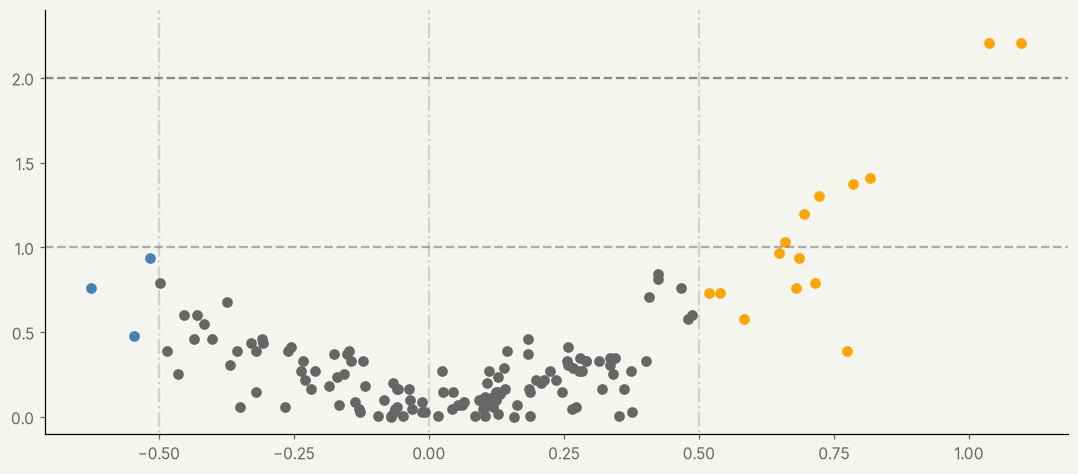

In [67]:
fig, ax = plt.subplots(figsize=(12, 5))

blue_mask = df_comparisons["cohen_d"] < -0.5
red_mask = df_comparisons["cohen_d"] > 0.5
gray_mask = ~(blue_mask | red_mask)

ax.scatter(df_comparisons.loc[gray_mask, "cohen_d"], df_comparisons.loc[gray_mask, "log_p"], color = SUPPORT_COLOR)
ax.scatter(df_comparisons.loc[blue_mask, "cohen_d"], df_comparisons.loc[blue_mask, "log_p"], color = "steelblue")
ax.scatter(df_comparisons.loc[red_mask, "cohen_d"], df_comparisons.loc[red_mask, "log_p"], color = "orange")

# ax.set_xlim(-1, 1)
ax.set_ylim(-0.1, 2.4)
ax.vlines([-0.5, 0, 0.5], ymin=-0.2, ymax=2.5, colors=SUPPORT_COLOR, alpha = 0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label = "p = 0.01", color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
ax.axhline(-np.log10(0.1), label = "p = 0.1", color=SUPPORT_COLOR, alpha = 0.5, linestyle="--")

plt.show()

In [68]:
df_comparisons.loc[blue_mask | red_mask, :].sort_values(by="p")

,Location,Band,Rest,p,cohen_d,log_p
0,ANT_FRONTAL,delta,0,0.006197,1.036844,2.207842
5,ANT_FRONTAL,all,0,0.006197,1.097023,2.207842
42,ALL_FRONTAL,delta,0,0.038816,0.816504,1.410993
90,ALL_FRONTAL,delta,1,0.042273,0.784275,1.373932
95,ALL_FRONTAL,all,1,0.049975,0.722883,1.301250
53,ANT_FRONTAL,all,1,0.063707,0.694930,1.195813
33,TEMPORAL,beta,0,0.093419,0.659173,1.029565
54,FRONTAL,delta,1,0.108055,0.647431,0.966353
88,ALL_CHANNELS,gamma,1,0.116026,-0.516526,0.935446
47,ALL_FRONTAL,all,0,0.116026,0.685545,0.935446


In [69]:
del df_comparisons

Specifically compare the increased PCE (decreased synchronization) between before and after the task was given. Same test as the paper.

In [70]:
from scipy.stats import wilcoxon

df_increase = df[df["Rest"] == 0].copy()
df_increase["PCE_calc"] = df_increase["PCE"].values
df_increase["PCE_rest"] = df.loc[df["Rest"] == 1, "PCE"].values # type: ignore
df_increase = df_increase.drop(columns = ["PCE"])

res = []

for ch in df_increase["Location"].unique():
    channel_mask = df_increase["Location"] == ch
    for band in df_increase["Band"].unique():
        band_mask = df_increase["Band"] == band
        
        for good_counters in [0, 1, 2]:
            counters_mask = df_increase["Count quality"] == good_counters
            if good_counters == 2:
                counters_mask = df_increase["Count quality"] < 2
                 
            df_case = df_increase.loc[channel_mask & band_mask & counters_mask, :]
            _, p = wilcoxon(df_case["PCE_calc"], df_case["PCE_rest"], alternative="greater")
            effect_size = cohen_d(df_case["PCE_calc"].values, df_case["PCE_rest"].values)

            res.append({
                    "Location" : ch,
                    "Band" : band,
                    "Counters" : "Good" if good_counters == 1 else "Poor" if good_counters == 0 else "All",
                    "p" : p,
                    "cohen_d" : effect_size,
                    "color" : "orange" if good_counters == 1 else "steelblue" if good_counters == 0 else "forestgreen",
                    })

df_wilcoxon = pd.DataFrame(res)
df_wilcoxon["log_p"] = -np.log10(df_wilcoxon["p"])
df_wilcoxon.to_csv(RESULTS_FOLDER / "wilcoxon.csv")
df_wilcoxon[df_wilcoxon["p"] < 0.01].sort_values(by="cohen_d", ascending=False)

,Location,Band,Counters,p,cohen_d,color,log_p
129,ALL_FRONTAL,theta,Poor,9.765625e-04,1.349588,steelblue,3.010300
132,ALL_FRONTAL,alpha,Poor,9.765625e-04,0.955342,steelblue,3.010300
131,ALL_FRONTAL,theta,All,8.029645e-06,0.935008,forestgreen,5.095304
134,ALL_FRONTAL,alpha,All,5.768379e-07,0.933910,forestgreen,6.238946
133,ALL_FRONTAL,alpha,Good,9.514391e-05,0.929468,orange,4.021619
23,FRONTAL,theta,All,1.448906e-04,0.878532,forestgreen,3.838960
26,FRONTAL,alpha,All,1.163469e-05,0.823711,forestgreen,4.934245
130,ALL_FRONTAL,theta,Good,8.897781e-04,0.820475,orange,3.050718
25,FRONTAL,alpha,Good,2.325475e-04,0.805579,orange,3.633488
22,FRONTAL,theta,Good,2.566591e-03,0.788291,orange,2.590643


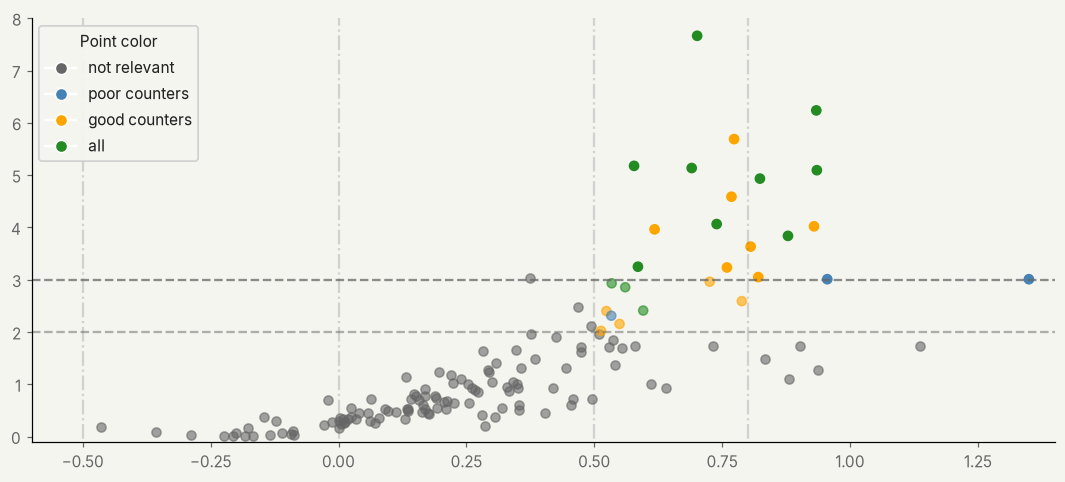

In [71]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(12, 5))

gray_mask = (df_wilcoxon["p"] > 0.01) | (abs(df_wilcoxon["cohen_d"]) < 0.5)
color_mask = (df_wilcoxon["p"] <= 0.001) & (abs(df_wilcoxon["cohen_d"] >= 0.5))
alpha_mask = ~(gray_mask | color_mask)

ax.scatter(df_wilcoxon.loc[gray_mask, "cohen_d"], df_wilcoxon.loc[gray_mask, "log_p"], color=SUPPORT_COLOR, alpha=0.6)
ax.scatter(df_wilcoxon.loc[alpha_mask, "cohen_d"], df_wilcoxon.loc[alpha_mask, "log_p"], color=df_wilcoxon.loc[alpha_mask, "color"], alpha = 0.6)
ax.scatter(df_wilcoxon.loc[color_mask, "cohen_d"], df_wilcoxon.loc[color_mask, "log_p"], color=df_wilcoxon.loc[color_mask, "color"])


ax.set_xlim(-0.6, 1.4)
ax.set_ylim(-0.1, 8)
ax.vlines([-0.5, 0, 0.5, 0.8], ymin=-0.5, ymax=10, colors=SUPPORT_COLOR, alpha=0.25, linestyles="-.")
ax.axhline(-np.log10(0.01), label="p = 0.01", color=SUPPORT_COLOR, alpha=0.5, linestyle="--")
ax.axhline(-np.log10(0.001), label="p = 0.001", color=SUPPORT_COLOR, alpha=0.75, linestyle="--")

color_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=SUPPORT_COLOR, markersize=8, label="not relevant"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue", markersize=8, label="poor counters"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="orange", markersize=8, label="good counters"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="forestgreen", markersize=8, label="all"),
]

# Keep the existing p-value line labels in a second legend
handles, labels = ax.get_legend_handles_labels()
legend1 = ax.legend(handles=color_legend, loc="upper left", title="Point color", frameon=True)
ax.add_artist(legend1)
# ax.legend(loc="upper right", frameon=False)

plt.savefig(FIGURES_FOLDER / "effect_task.png", dpi = 600)
plt.show()

In [72]:
del df_wilcoxon

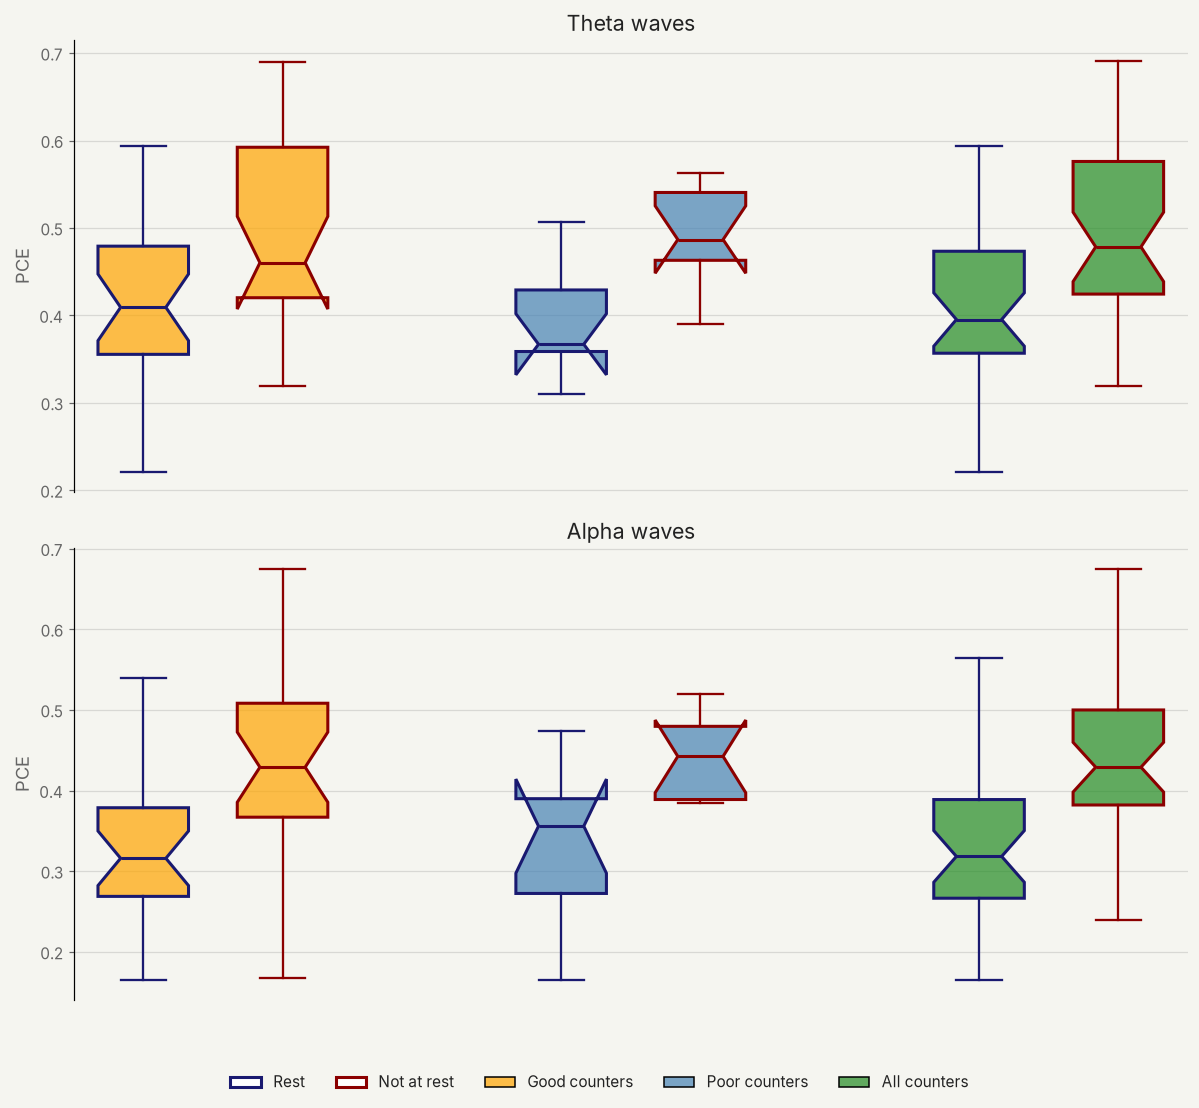

In [73]:
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba

alpha_mask = df["Band"] == "alpha"
theta_mask = df["Band"] == "theta"
channel_mask = df["Location"] == "ALL_FRONTAL"
 
df_boxplot = df[channel_mask & (alpha_mask | theta_mask)]

# Face colors: counter quality
quality_colors = {
    1: "orange",
    0: "steelblue",
    "both": "forestgreen"
}

# Edge colors: rest condition
rest_edge_colors = {
    1: "midnightblue",  # Rest
    0: "darkred"    # Not at rest
}

# Face transparency
face_alpha = 0.7

# X positions
positions = {
    1: [1, 2],
    0: [4, 5],
    "both": [7, 8]
}

groups = [1, 0, "both"]

# Create figure
fig, axes = plt.subplots(2, 1, figsize=(11, 10))

for ax, band in zip(axes, ["theta", "alpha"]):

    band_df = df_boxplot[df_boxplot["Band"] == band]

    for group in groups:

        # Select observations
        if group == "both":
            subset = band_df
        else:
            subset = band_df[band_df["Count quality"] == group]

        # Data for Rest = 1 and Rest = 0
        data = [
            subset[subset["Rest"] == rest]["PCE"].dropna()
            for rest in [1, 0]
        ]

        pos = positions[group]
        face_color = quality_colors[group]

        # Draw boxplots
        bp = ax.boxplot(
            data,
            positions=pos,
            widths=0.65,
            patch_artist=True,
            notch=True,
            showfliers=False,
            boxprops=dict(linewidth=2),
            whiskerprops=dict(linewidth=1.5),
            capprops=dict(linewidth=1.5),
            medianprops=dict(linewidth=2)
        )

        # Customize each box and its associated lines
        for i, rest in enumerate([1, 0]):

            edge_color = rest_edge_colors[rest]

            # Box: transparent face, fully opaque edge
            bp["boxes"][i].set_facecolor(
                to_rgba(face_color, alpha=face_alpha)
            )
            bp["boxes"][i].set_edgecolor(edge_color)
            bp["boxes"][i].set_linewidth(2)

            # Whiskers
            for whisker in bp["whiskers"][2*i:2*i+2]:
                whisker.set_color(edge_color)

            # Caps
            for cap in bp["caps"][2*i:2*i+2]:
                cap.set_color(edge_color)

            # Median
            bp["medians"][i].set_color(edge_color)

    # Axis formatting
    # ax.set_xticks([1.5, 4.5, 7.5])
    # ax.set_xticklabels([
    #     "Good counters",
    #     "Poor counters",
    #     "All counters"
    # ])

    ax.set_ylabel("PCE", fontsize=12)
    ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    ax.set_title(f"{band.capitalize()} waves", fontsize=14)
    ax.grid(axis="y", linestyle="-", color = SUPPORT_COLOR, alpha=0.2)
    ax.set_axisbelow(True)

# Legend: edge colors = Rest condition
rest_legend = [
    Patch(
        facecolor="white",
        edgecolor=rest_edge_colors[1],
        linewidth=2,
        label="Rest"
    ),
    Patch(
        facecolor="white",
        edgecolor=rest_edge_colors[0],
        linewidth=2,
        label="Not at rest"
    )
]

# Legend: face colors = counter quality
quality_legend = [
    Patch(
        facecolor=to_rgba(quality_colors[1], face_alpha),
        edgecolor="black",
        label="Good counters"
    ),
    Patch(
        facecolor=to_rgba(quality_colors[0], face_alpha),
        edgecolor="black",
        label="Poor counters"
    ),
    Patch(
        facecolor=to_rgba(quality_colors["both"], face_alpha),
        edgecolor="black",
        label="All counters"
    )
]

fig.legend(
    handles=rest_legend + quality_legend,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig(FIGURES_FOLDER / "boxplots.png", dpi = 600)
plt.show()



## PCE in time

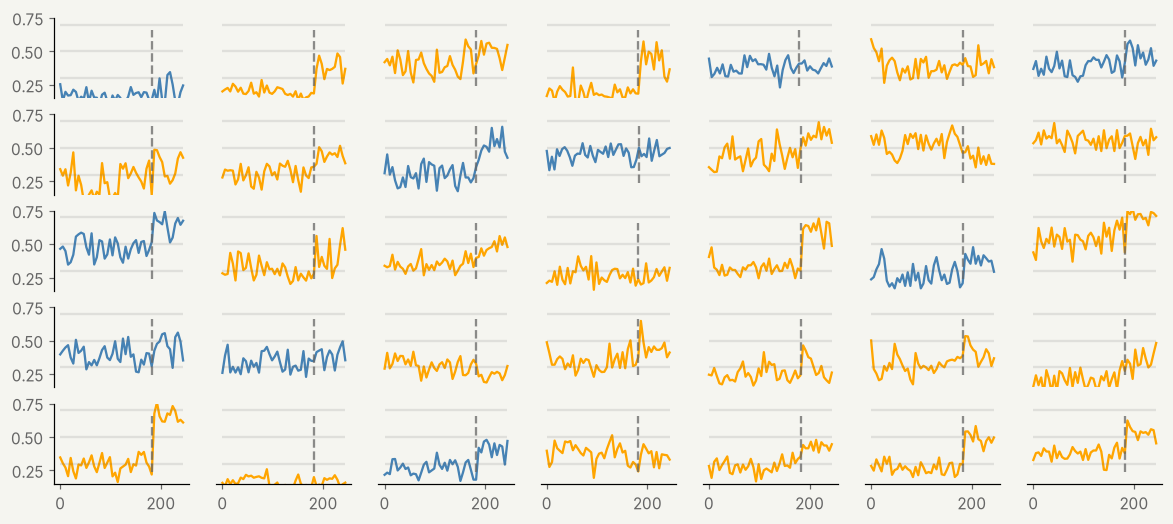

In [74]:
from _PCE import short_term_PCE
from _processing import extract_band

fig, axes = plt.subplots(5, 7, figsize = (13, 5.5))

subjects = user_df["Subject"].unique()
channel = "ALL_FRONTAL"
band = "alpha"
OVERLAP = 5

for it in range(user_df["Subject"].nunique()):
    sbj = subjects[it]
    sbj_info = user_df.loc[user_df["Subject"] == sbj]
    
    # User's 31 rest phase is incomplete (1 minute instead of 3)
    if it == 31:
        continue
    if it > 31:
        it -= 1
        
    i = it // 7
    j = it % 7
    color = "steelblue" if sbj_info["Count quality"].values[0] == 0 else "orange"
    
    rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
    rest_np = np.array(rest_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
    rest_band = extract_band(rest_np, band, Fs)
    timeline = short_term_PCE(rest_band, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP, do_decimate = DECIMATE)
    
    calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_2.edf", verbose=False)
    calc_np = np.array(calc_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
    calc_band = extract_band(calc_np, band, Fs)
    timeline += short_term_PCE(calc_band, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP, do_decimate = DECIMATE)
    
    full = np.concat((rest_band, calc_band), axis = 1)
 
    
    if j != 0:
        axes[i, j].spines["left"].set_visible(False)
        axes[i, j].set_yticks([])
        
    if i != 4:
        axes[i, j].spines["bottom"].set_visible(False)
        axes[i, j].set_xticks([])
        
    t_max = full.shape[1] / Fs
    t = np.linspace(0, t_max, len(timeline))
    task_start = rest_np.shape[1] / Fs
    
    # time_full = short_term_PCE(full, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP)
    # axes[i, j].plot(np.linspace(0, t_max, len(time_full)), time_full, color = "black")
    
    axes[i, j].plot(t, timeline, color = color)
    axes[i, j].set_ylim(0.15, 0.75)
    axes[i, j].hlines([0.3, 0.5, 0.7], xmin = 0, xmax = t_max, colors = SUPPORT_COLOR, alpha = 0.15)
    
    axes[i, j].axvline(task_start, ymin = 0.15, ymax = 0.85, color=SUPPORT_COLOR, alpha = 0.75, linestyle="--")
    
plt.savefig(FIGURES_FOLDER / "mini_muliples.png", dpi = 600)

## Surrogate signals

In [75]:
channel = "ALL_FRONTAL"
band = "alpha"
sbj = "Subject18"
N_SURROGATES = 500

sbj_info = user_df.loc[user_df["Subject"] == sbj]
color = "steelblue" if sbj_info["Count quality"].values[0] == 0 else "orange"

In [76]:
rest_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_1.edf", verbose=False)
rest_np = np.array(rest_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
rest_band = extract_band(rest_np, band, Fs)
timeline = short_term_PCE(rest_band, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP, do_decimate = DECIMATE)
    
calc_raw = mne.io.read_raw_edf(DATA_FOLDER / f"{sbj}_2.edf", verbose=False)
calc_np = np.array(calc_raw[["EEG " + ch for ch in CHANNELS[channel]]][0])
calc_band = extract_band(calc_np, band, Fs)
timeline += short_term_PCE(calc_band, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP, do_decimate = DECIMATE)
    
# full = np.concat((rest_band, calc_band), axis = 1)
# timeline = short_term_PCE(full, Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP)

In [77]:
from _processing import surrogate

surrogates_rest = surrogate(rest_band, n=N_SURROGATES)
surrogates_calc = surrogate(calc_band, n=N_SURROGATES)

surrogates_PCE = np.zeros((N_SURROGATES, len(timeline)))
for i in range(N_SURROGATES):
    surr_timeline = short_term_PCE(surrogates_rest[i], Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP)
    surr_timeline += short_term_PCE(surrogates_calc[i], Fs = Fs, window_size=WINDOW_SIZE, overlap = OVERLAP)
    surrogates_PCE[i] = surr_timeline
    
surrogates_mean = np.mean(surrogates_PCE, axis = 0)
surrogates_std = np.std(surrogates_PCE, axis = 0)

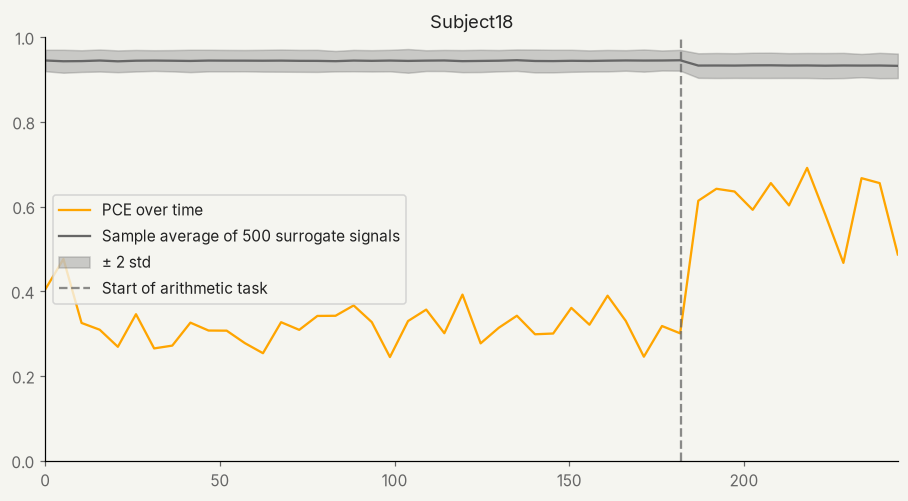

In [78]:
t_max = full.shape[1] / Fs
t = np.linspace(0, t_max, len(timeline))
task_start = rest_np.shape[1] / Fs

fig, ax = plt.subplots(figsize = (10, 5))

ax.plot(t, timeline, color=color, label="PCE over time")

ax.plot(t, surrogates_mean, color = SUPPORT_COLOR, label = f"Sample average of {N_SURROGATES} surrogate signals")
ax.fill_between(t, surrogates_mean - 2 * surrogates_std,
                surrogates_mean + 2 * surrogates_std, alpha=0.3, color = SUPPORT_COLOR,
                label="± 2 std")    # shaded error band

ax.axvline(task_start, color=SUPPORT_COLOR, alpha = 0.75, linestyle="--", label = "Start of arithmetic task")

ax.set_title(f"{sbj}")
ax.set_xlim(0, t_max)
ax.set_ylim(0, 1)
ax.legend()

plt.savefig(FIGURES_FOLDER / "surrogates.png", dpi = 600)
plt.show()

In [79]:
del calc_band, calc_np, calc_raw, rest_band, rest_np, rest_raw
del surrogates_PCE, surrogates_calc, surrogates_rest